In [27]:
import pandas as pd
import numpy as np

In [5]:
df = pd.read_csv('dataset_berita.csv')
df.head(20)

,Teks,Media,Label
0,"Liputan6.com, Jakarta - Mantan pelatih Liverpo...",Liputan6.com,Liga Inggris
1,"Liputan6.com, Jakarta - Manchester United kini...",Liputan6.com,Liga Inggris
2,"Liputan6.com, Jakarta - Persaingan untuk menda...",Liputan6.com,Liga Inggris
3,"Liputan6.com, Jakarta - Manchester United berp...",Liputan6.com,Liga Inggris
4,"Liputan6.com, Jakarta - Manchester United masi...",Liputan6.com,Liga Inggris
5,"Liputan6.com, Jakarta - Manchester United akti...",Liputan6.com,Liga Inggris
6,"Liputan6.com, Jakarta - Gelandang Brasil Eders...",Liputan6.com,Liga Inggris
7,"Liputan6.com, Jakarta - Manchester United hamp...",Liputan6.com,Liga Inggris
8,"Liputan6.com, Jakarta - Manchester United teru...",Liputan6.com,Liga Inggris
9,"Liputan6.com, Jakarta - Nasib Marcus Rashford ...",Liputan6.com,Liga Inggris


#Data Cleaning and Exploratory Data Analysis

In [6]:
print(df.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 3 columns):
 #   Column  Non-Null Count  Dtype 
---  ------  --------------  ----- 
 0   Teks    1000 non-null   object
 1   Media   1000 non-null   object
 2   Label   1000 non-null   object
dtypes: object(3)
memory usage: 23.6+ KB
None


In [7]:
print(df.isnull().sum())

Teks     0
Media    0
Label    0
dtype: int64


In [8]:
print(df.duplicated().sum())
df.drop_duplicates(inplace=True)

0


In [9]:
sample_liputan = df[df['Media'].isin(['Liputan6.com'])].sample(n=1, random_state=42)
sample_detik = df[df['Media'].isin(['Detik.com'])].sample(n=1, random_state=42)

In [10]:
teks_liputan = sample_liputan['Teks'].values[0]
print(teks_liputan)
#it needs a bit cleaning

Liputan6.com, Jakarta- Rapat Umum Pemegang Saham (RUPS) digelar PT Liga Indonesia Baru atau LIB pada Senin (7/7/2025) di The Langham Jakarta. Sejumlah keputusan strategis dihasilkan dalam RUPS yang baru selesai pukul 20.30 WIB itu. Yang paling menyedot perhatian adalah perubahan nama kompetisi tertinggi di Indonesia BRI Liga 1. Mulai musim 2025/2026, nama resmi kompetis berganti menjadi BRI Super League. Perubahan juga terjadi di Liga 2 yang akan bernama Pengadaian Championship. "Mulai musim ini [2025/2026] kami melakukan rebranding dengan mengusung nama BRI Super League untuk Liga 1 dan Pegadaian Championship untuk Liga 2," kata Direktur Utama PT LIB Ferry Paulus di Jakarta, Senin (7/7/2025).


In [11]:
teks_detik = sample_detik['Teks'].values[0]
print(teks_detik)

Timnas Indonesia U-19 akan menjalani pertandingan perebutan tempat ketiga Piala AFF U-19 2026. Garuda Muda pernah tiga kali finis ketiga. Kamboja yang akan menjadi lawan Indonesia di laga perebutan tempat ketiga ajang Piala AFF U-19 2026. Laga itu akan berlangsung di Stadion Utama Sumatera Utara, Deli Serdang, Sabtu (13/6/2026) sore WIB. Indonesia gagal ke final setelah kalah tipis dari Australia 0-1. Sementara itu, Kamboja dihajar oleh Thailand dengan skor 0-4 di semifinal. SCROLL TO CONTINUE WITH CONTENT Dalam 13 kali keikutsertaan di Piala AFF U-19, Indonesia empat kali gagal ke final saat bisa menembus empat besar. Sebelumnya, Indonesia juga kalah di semifinal pada tahun 2017, 2018, dan 2019. Indonesia selalu finis ketiga saat gagal lolos ke final. Indonesia mempunyai modal bagus menatap duel dengan Kamboja. Dalam tiga pertemuan dengan Kamboja di Piala AFF U-19, Indonesia selalu menang. Indonesia mampu tujuh kali menjebol gawang Kamboja, cuma kebobolan tiga kali. Indonesia juga bis

In [12]:
import re
DATELINE_DASH = re.compile(r"^\s*(?:Liputan6\.com)\s*,\s*[A-Z][a-zA-Z]+(?:\s[A-Z][a-zA-Z]+)?\s*[-–]\s*")

def cleaning(text):
  text = str(text)
  text = re.sub(DATELINE_DASH, "", text)
  text = text.lower()
  text = re.sub(r'\s+', ' ', text).strip()
  return text

In [13]:
df["cleaned_text"] = df["Teks"].apply(cleaning)

In [14]:
df[["Teks", "cleaned_text"]].head()

,Teks,cleaned_text
0,"Liputan6.com, Jakarta - Mantan pelatih Liverpo...",mantan pelatih liverpool jürgen klopp memberi ...
1,"Liputan6.com, Jakarta - Manchester United kini...",manchester united kini kembali menghadapi isu ...
2,"Liputan6.com, Jakarta - Persaingan untuk menda...",persaingan untuk mendapatkan tanda tangan gela...
3,"Liputan6.com, Jakarta - Manchester United berp...",manchester united berpotensi memanfaatkan kete...
4,"Liputan6.com, Jakarta - Manchester United masi...",manchester united masih aktif dalam kegiatan b...


Word cloud for Liga Inggris star reviews:


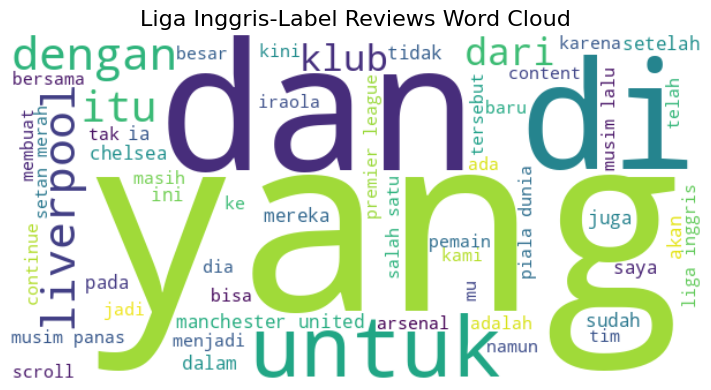

Word cloud for Liga Indonesia star reviews:


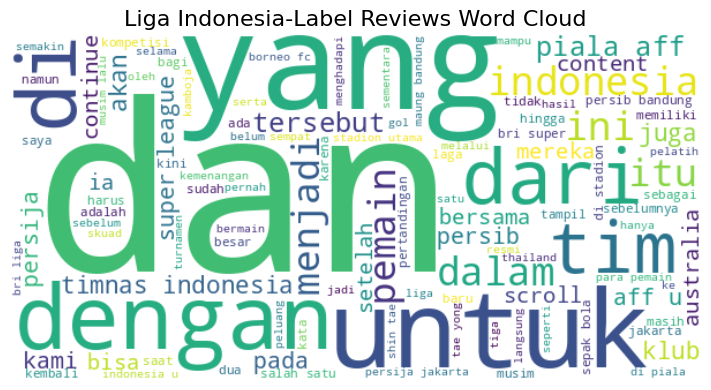

Word cloud for Liga Spanyol star reviews:


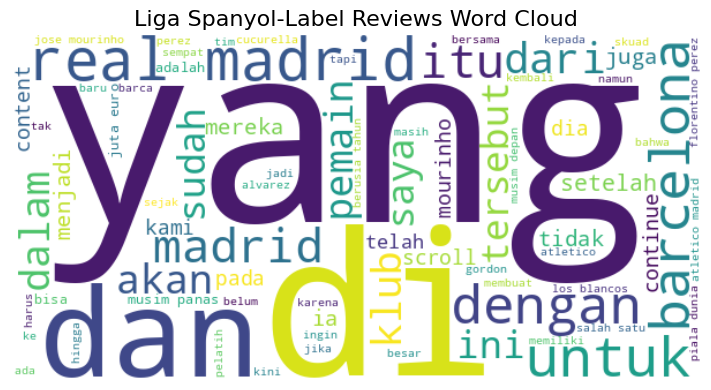

Word cloud for Liga Italia star reviews:


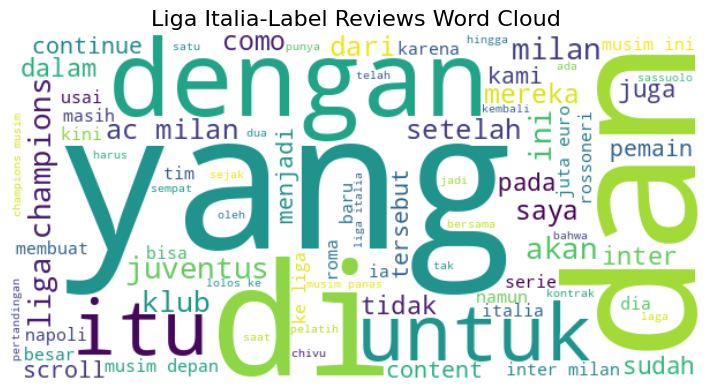

Word cloud for Olahraga Non Sepak Bola star reviews:


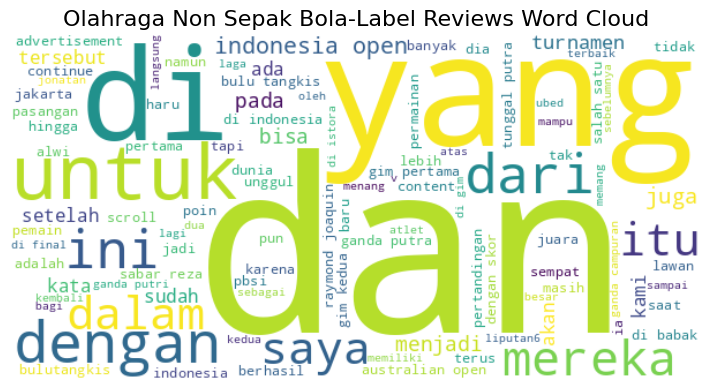

In [15]:
# Local Word Cloud (with stopwords)
from wordcloud import WordCloud
import matplotlib.pyplot as plt
def generate_label_wordcloud(df, label):
  print(f"Word cloud for {label} star reviews:")

  text_data = df[df['Label'] == label]['cleaned_text'].astype(str)
  combined_text = " ".join(text_data)

  wordcloud = WordCloud(
      width=600,
      height=300,
      background_color='white',
      # stopwords=stopwords,
      colormap='viridis',
      min_font_size=10
  ).generate(combined_text)

  plt.figure(figsize=(8, 4))
  plt.imshow(wordcloud, interpolation='bilinear')
  plt.title(f'{label}-Label Reviews Word Cloud', fontsize=16)
  plt.axis('off') # Hide axes
  plt.tight_layout()
  plt.show()

for current_label in ['Liga Inggris', 'Liga Indonesia', 'Liga Spanyol', 'Liga Italia', 'Olahraga Non Sepak Bola']:
  generate_label_wordcloud(df, current_label)

In [16]:
pip install nltk

In [17]:
import nltk
from nltk.corpus import stopwords

nltk.download('stopwords')

[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Unzipping corpora/stopwords.zip.


True

Word cloud for Liga Inggris star reviews:


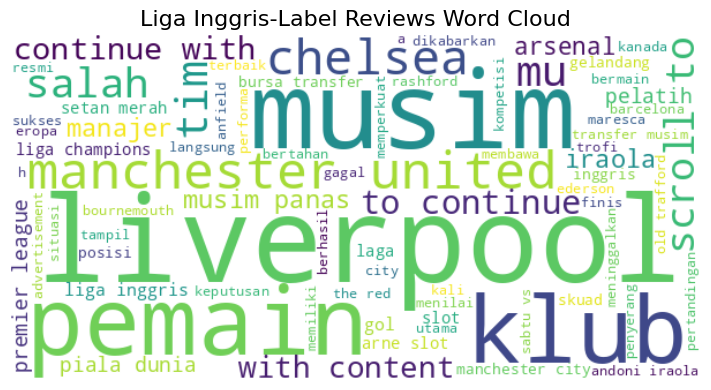

Word cloud for Liga Indonesia star reviews:


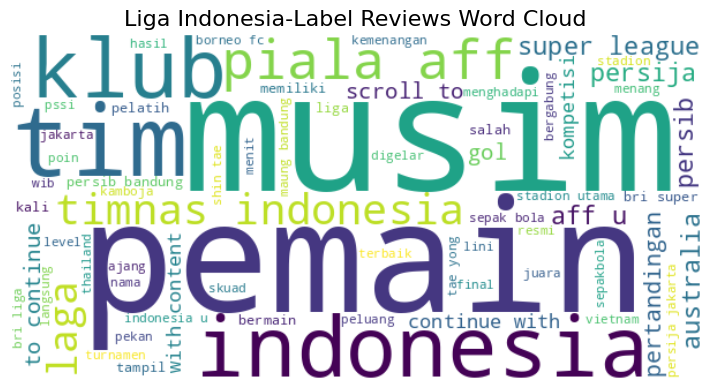

Word cloud for Liga Spanyol star reviews:


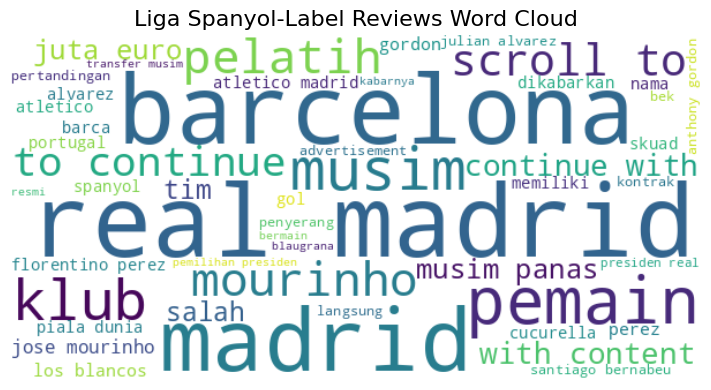

Word cloud for Liga Italia star reviews:


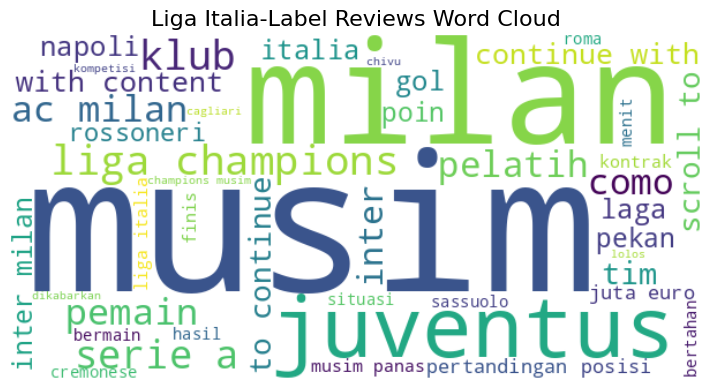

Word cloud for Olahraga Non Sepak Bola star reviews:


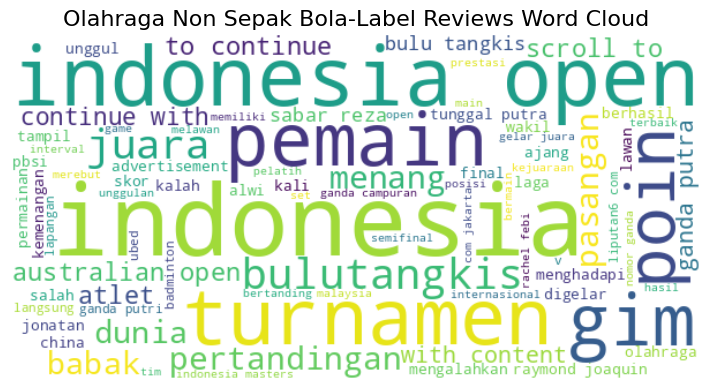

In [18]:
# Local Word Cloud (without stopwords)
from wordcloud import WordCloud
import matplotlib.pyplot as plt

custom_stopwords = set(stopwords.words('indonesian'))

def generate_label_wordcloud(df, label):
  print(f"Word cloud for {label} star reviews:")

  text_data = df[df['Label'] == label]['cleaned_text'].astype(str)
  combined_text = " ".join(text_data)

  wordcloud = WordCloud(
      width=600,
      height=300,
      background_color='white',
      stopwords=custom_stopwords,
      colormap='viridis',
      min_font_size=10
  ).generate(combined_text)

  plt.figure(figsize=(8, 4))
  plt.imshow(wordcloud, interpolation='bilinear')
  plt.title(f'{label}-Label Reviews Word Cloud', fontsize=16)
  plt.axis('off') # Hide axes
  plt.tight_layout()
  plt.show()

for current_label in ['Liga Inggris', 'Liga Indonesia', 'Liga Spanyol', 'Liga Italia', 'Olahraga Non Sepak Bola']:
  generate_label_wordcloud(df, current_label)

In [19]:
from sklearn.model_selection import train_test_split
from datasets import Dataset

def prepare_three_way_split(dataframe):
    train_df, temp_df = train_test_split(dataframe, test_size=0.3, random_state=42)
    val_df, test_df = train_test_split(temp_df, test_size=0.5, random_state=42)

    train_ds = Dataset.from_pandas(train_df).map(tokenize_function, batched=True)
    val_ds = Dataset.from_pandas(val_df).map(tokenize_function, batched=True)
    test_ds = Dataset.from_pandas(test_df).map(tokenize_function, batched=True)

    return train_ds, val_ds, test_ds

In [20]:
from transformers import AutoTokenizer

MODEL_NAME = "indobenchmark/indobert-base-p1"
tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)

def tokenize_function(examples):
    return tokenizer(examples["text"], padding="max_length", truncation=True, max_length=512)

/usr/local/lib/python3.12/dist-packages/huggingface_hub/utils/_auth.py:124: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


config.json:   0%|          | 0.00/1.53k [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/2.00 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/229k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

In [21]:
label_map_5_class = {
    'Olahraga Non Sepak Bola': 0,
    'Liga Inggris': 1,
    'Liga Indonesia': 2,
    'Liga Spanyol': 3,
    'Liga Italia': 4
}

df['label_1_stage'] = df['Label'].map(label_map_5_class)

In [22]:
pip install evaluate

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 84.1/84.1 kB 6.2 MB/s eta 0:00:00


In [23]:
import evaluate
metric = evaluate.load("accuracy")
def compute_metrics(eval_pred):
    logits, labels = eval_pred
    predictions = np.argmax(logits, axis=-1)
    return metric.compute(predictions=predictions, references=labels)

In [24]:
pip install optuna

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 425.6/425.6 kB 25.7 MB/s eta 0:00:00


In [25]:
def optuna_hp_space(trial):
    return {
        "learning_rate": trial.suggest_categorical("learning_rate", [2e-5, 5e-5]),
        "per_device_train_batch_size": trial.suggest_categorical("per_device_train_batch_size", [8, 16])
    }

# Model 1

In [28]:
from transformers import Trainer, AutoModelForSequenceClassification, TrainingArguments

df_model1 = df[['cleaned_text', 'label_1_stage']].rename(columns={'cleaned_text': 'text', 'label_1_stage': 'label'})
train_ds1, val_ds1, test_ds1 = prepare_three_way_split(df_model1)

def model_init_1_stage():
    return AutoModelForSequenceClassification.from_pretrained(MODEL_NAME, num_labels=5)

training_args1 = TrainingArguments(
    output_dir="./results_1_stage",
    eval_strategy="epoch",
    save_strategy="epoch",
    num_train_epochs=3,
    disable_tqdm=True
)

trainer1 = Trainer(
    model_init=model_init_1_stage,
    args=training_args1,
    train_dataset=train_ds1,
    eval_dataset=val_ds1,
    compute_metrics=compute_metrics,
)

best_run_1 = trainer1.hyperparameter_search(
    direction="maximize",
    backend="optuna",
    hp_space=optuna_hp_space,
    n_trials=2
)

Map:   0%|          | 0/700 [00:00<?, ? examples/s]

Map:   0%|          | 0/150 [00:00<?, ? examples/s]

Map:   0%|          | 0/150 [00:00<?, ? examples/s]

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertForSequenceClassification LOAD REPORT from: indobenchmark/indobert-base-p1
Key               | Status  | 
------------------+---------+-
classifier.weight | MISSING | 
classifier.bias   | MISSING | 

Notes:
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.
[I 2026-06-30 03:56:53,734] A new study created in memory with name: no-name-8b919125-3e5b-40b0-a546-7e3c15a1d4e1


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

... (15 outputs left out)

{'eval_loss': '0.1138', 'eval_accuracy': '0.9667', 'eval_runtime': '4.4', 'eval_samples_per_second': '34.09', 'eval_steps_per_second': '4.318', 'epoch': '3'}


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

{'train_runtime': '342.7', 'train_samples_per_second': '6.129', 'train_steps_per_second': '0.385', 'train_loss': '0.3134', 'epoch': '3'}


[I 2026-06-30 04:07:57,507] Trial 1 finished with value: 0.9666666666666667 and parameters: {'learning_rate': 5e-05, 'per_device_train_batch_size': 16}. Best is trial 0 with value: 0.9666666666666667.


In [34]:
import seaborn as sns
from sklearn.metrics import classification_report, confusion_matrix

trainer1.args.learning_rate = best_run_1.hyperparameters['learning_rate']
trainer1.args.per_device_train_batch_size = best_run_1.hyperparameters['per_device_train_batch_size']
trainer1.args.logging_strategy = "epoch"
trainer1.train()

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertForSequenceClassification LOAD REPORT from: indobenchmark/indobert-base-p1
Key               | Status  | 
------------------+---------+-
classifier.weight | MISSING | 
classifier.bias   | MISSING | 

Notes:
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


{'loss': '0.8684', 'grad_norm': '4.107', 'learning_rate': '1.348e-05', 'epoch': '1'}
{'eval_loss': '0.2188', 'eval_accuracy': '0.94', 'eval_runtime': '4.358', 'eval_samples_per_second': '34.42', 'eval_steps_per_second': '4.36', 'epoch': '1'}


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

{'loss': '0.1639', 'grad_norm': '3.231', 'learning_rate': '6.818e-06', 'epoch': '2'}
{'eval_loss': '0.1501', 'eval_accuracy': '0.9467', 'eval_runtime': '4.381', 'eval_samples_per_second': '34.24', 'eval_steps_per_second': '4.337', 'epoch': '2'}


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

{'loss': '0.09638', 'grad_norm': '5.861', 'learning_rate': '1.515e-07', 'epoch': '3'}
{'eval_loss': '0.1083', 'eval_accuracy': '0.9667', 'eval_runtime': '4.335', 'eval_samples_per_second': '34.6', 'eval_steps_per_second': '4.383', 'epoch': '3'}


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

{'train_runtime': '336.4', 'train_samples_per_second': '6.242', 'train_steps_per_second': '0.392', 'train_loss': '0.3762', 'epoch': '3'}


TrainOutput(global_step=132, training_loss=0.3762475432771625, metrics={'train_runtime': 336.4461, 'train_samples_per_second': 6.242, 'train_steps_per_second': 0.392, 'train_loss': 0.3762475432771625, 'epoch': 3.0})

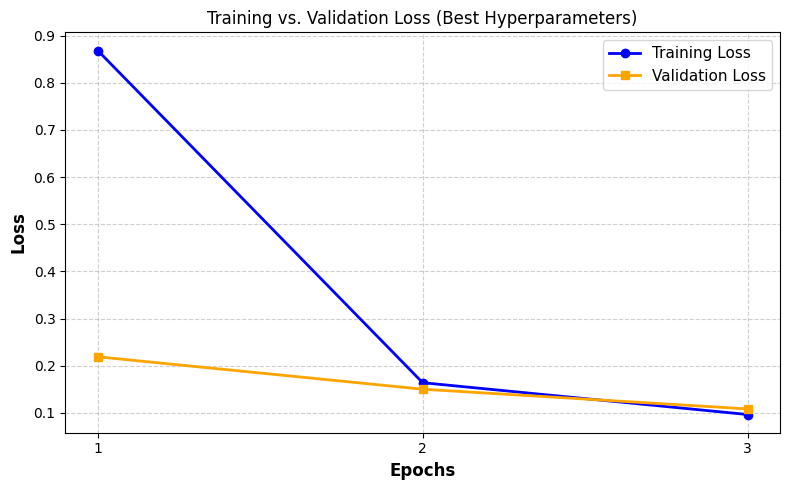

In [35]:
history = trainer1.state.log_history

train_loss_history = []
val_loss_history = []

for log in history:
    if 'loss' in log and 'epoch' in log:
        train_loss_history.append({'Epoch': log['epoch'], 'Training Loss': log['loss']})
    if 'eval_loss' in log and 'epoch' in log:
        val_loss_history.append({'Epoch': log['epoch'], 'Validation Loss': log['eval_loss']})

df_train = pd.DataFrame(train_loss_history)
df_val = pd.DataFrame(val_loss_history)

df_train = df_train.groupby('Epoch', as_index=False).mean()
df_val = df_val.groupby('Epoch', as_index=False).mean()

df_metrics = pd.merge(df_train, df_val, on='Epoch', how='outer').sort_values('Epoch')

plt.figure(figsize=(8, 5))
plt.plot(df_metrics['Epoch'], df_metrics['Training Loss'], label='Training Loss', color='blue', marker='o', linewidth=2)
plt.plot(df_metrics['Epoch'], df_metrics['Validation Loss'], label='Validation Loss', color='orange', marker='s', linewidth=2)

plt.title('Training vs. Validation Loss (Best Hyperparameters)')
plt.xlabel('Epochs', fontsize=12, fontweight='bold')
plt.ylabel('Loss', fontsize=12, fontweight='bold')
plt.grid(True, linestyle='--', alpha=0.6)
plt.xticks(df_metrics['Epoch'])
plt.legend(fontsize=11)
plt.tight_layout()
plt.show()


--- CLASSIFICATION REPORT ---
                         precision    recall  f1-score   support

Olahraga Non Sepak Bola       1.00      1.00      1.00        33
           Liga Inggris       0.96      0.93      0.95        28
         Liga Indonesia       1.00      1.00      1.00        22
           Liga Spanyol       0.90      1.00      0.95        26
            Liga Italia       1.00      0.95      0.97        41

               accuracy                           0.97       150
              macro avg       0.97      0.98      0.97       150
           weighted avg       0.98      0.97      0.97       150



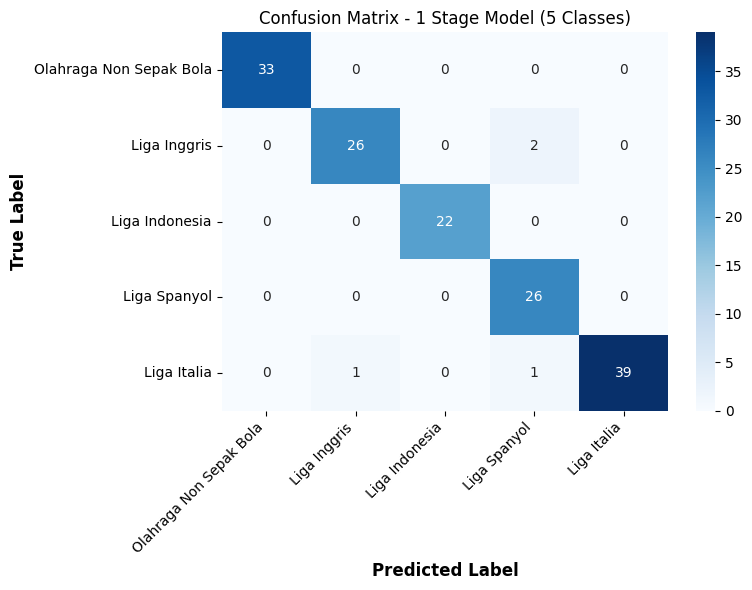

In [33]:
predictions_output = trainer1.predict(test_ds1)

y_pred = np.argmax(predictions_output.predictions, axis=1)
y_true = predictions_output.label_ids

inverse_label_map = {
    0: 'Olahraga Non Sepak Bola',
    1: 'Liga Inggris',
    2: 'Liga Indonesia',
    3: 'Liga Spanyol',
    4: 'Liga Italia'
}
target_names = [inverse_label_map[i] for i in range(5)]

print("\n--- CLASSIFICATION REPORT ---")
print(classification_report(y_true, y_pred, target_names=target_names))

cm = confusion_matrix(y_true, y_pred)

plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=target_names,
            yticklabels=target_names)

plt.title('Confusion Matrix - 1 Stage Model (5 Classes)')
plt.xlabel('Predicted Label', fontsize=12, fontweight='bold')
plt.ylabel('True Label', fontsize=12, fontweight='bold')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

#Model 2

In [37]:
# Stage 1 Classification
df['label_stage_2_1'] = df['Label'].apply(lambda x: 0 if x == 'Olahraga Non Sepak Bola' else 1)
df_stage2_1 = df[['cleaned_text', 'label_stage_2_1']].rename(columns={'cleaned_text': 'text', 'label_stage_2_1': 'label'})

train_ds2_1, val_ds2_1, test_ds2_1 = prepare_three_way_split(df_stage2_1)

def model_init_stage_2_1():
    return AutoModelForSequenceClassification.from_pretrained(MODEL_NAME, num_labels=2)

trainer2_1 = Trainer(
    model_init=model_init_stage_2_1,
    args=TrainingArguments(output_dir="./results_stage_2_1", eval_strategy="epoch", logging_strategy="epoch", num_train_epochs=3),
    train_dataset=train_ds2_1,
    eval_dataset=val_ds2_1,
    compute_metrics=compute_metrics,
)
trainer2_1.train()
print("Model 2 Stage 1 (Binary) Test Performance:", trainer2_1.evaluate(test_ds2_1))


# Stage 2 classification
df_football = df[df['label_stage_2_1'] == 1].copy()
label_map_4_class = {
    'Liga Inggris': 0,
    'Liga Indonesia': 1,
    'Liga Spanyol': 2,
    'Liga Italia': 3
}
df_football['label_stage_2_2'] = df_football['Label'].map(label_map_4_class)
df_stage2_2 = df_football[['cleaned_text', 'label_stage_2_2']].rename(columns={'cleaned_text': 'text', 'label_stage_2_2': 'label'})

train_ds2_2, val_ds2_2, test_ds2_2 = prepare_three_way_split(df_stage2_2)

def model_init_stage_2_2():
    return AutoModelForSequenceClassification.from_pretrained(MODEL_NAME, num_labels=4)

trainer2_2 = Trainer(
    model_init=model_init_stage_2_2,
    args=TrainingArguments(output_dir="./results_stage_2_2", eval_strategy="epoch", logging_strategy="epoch", num_train_epochs=3),
    train_dataset=train_ds2_2,
    eval_dataset=val_ds2_2,
    compute_metrics=compute_metrics,
)
trainer2_2.train()
print("Model 2 Stage 2 (Leagues) Test Performance:", trainer2_2.evaluate(test_ds2_2))

Map:   0%|          | 0/700 [00:00<?, ? examples/s]

Map:   0%|          | 0/150 [00:00<?, ? examples/s]

Map:   0%|          | 0/150 [00:00<?, ? examples/s]

[transformers] You passed `num_labels=2` which is incompatible to the `id2label` map of length `5`.


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertForSequenceClassification LOAD REPORT from: indobenchmark/indobert-base-p1
Key               | Status  | 
------------------+---------+-
classifier.weight | MISSING | 
classifier.bias   | MISSING | 

Notes:
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.
[transformers] You passed `num_labels=2` which is incompatible to the `id2label` map of length `5`.


... (14 outputs left out)

Epoch,Training Loss,Validation Loss,Accuracy
1,0.600581,0.436220,0.916667
2,0.167013,0.410915,0.900000
3,0.096798,0.406801,0.925000


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Training Loss,Validation Loss,Epoch,Accuracy
0.096798,0.095297,3,0.983333


Model 2 Stage 2 (Leagues) Test Performance: {'eval_loss': 0.09529723227024078, 'eval_accuracy': 0.9833333333333333}


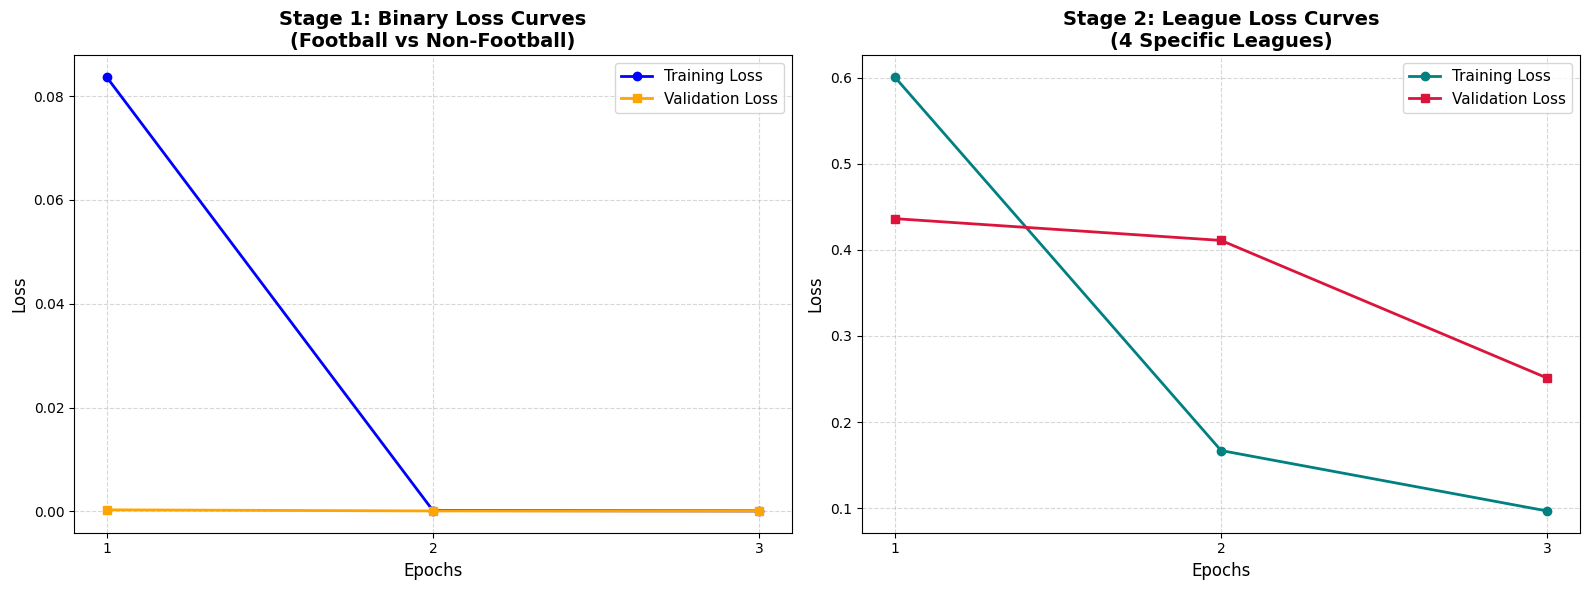

In [38]:
trainer2_1.args.logging_strategy = "epoch"
trainer2_2.args.logging_strategy = "epoch"

def extract_loss_history(trainer):
    history = trainer.state.log_history
    train_loss = []
    val_loss = []

    for log in history:
        if 'loss' in log and 'epoch' in log:
            train_loss.append({'Epoch': round(log['epoch']), 'Training Loss': log['loss']})
        if 'eval_loss' in log and 'epoch' in log:
            val_loss.append({'Epoch': round(log['epoch']), 'Validation Loss': log['eval_loss']})

    df_train = pd.DataFrame(train_loss).groupby('Epoch', as_index=False).mean()
    df_val = pd.DataFrame(val_loss).groupby('Epoch', as_index=False).mean()

    return pd.merge(df_train, df_val, on='Epoch', how='inner').sort_values('Epoch')

df_stage1 = extract_loss_history(trainer2_1)
df_stage2 = extract_loss_history(trainer2_2)

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

axes[0].plot(df_stage1['Epoch'], df_stage1['Training Loss'], label='Training Loss', color='blue', marker='o', linewidth=2)
axes[0].plot(df_stage1['Epoch'], df_stage1['Validation Loss'], label='Validation Loss', color='orange', marker='s', linewidth=2)
axes[0].set_title('Stage 1: Binary Loss Curves\n(Football vs Non-Football)', fontsize=14, fontweight='bold')
axes[0].set_xlabel('Epochs', fontsize=12)
axes[0].set_ylabel('Loss', fontsize=12)
axes[0].set_xticks(df_stage1['Epoch'])
axes[0].grid(True, linestyle='--', alpha=0.5)
axes[0].legend(fontsize=11)

# Plot Stage 2: Specific Leagues Classifier
axes[1].plot(df_stage2['Epoch'], df_stage2['Training Loss'], label='Training Loss', color='teal', marker='o', linewidth=2)
axes[1].plot(df_stage2['Epoch'], df_stage2['Validation Loss'], label='Validation Loss', color='crimson', marker='s', linewidth=2)
axes[1].set_title('Stage 2: League Loss Curves\n(4 Specific Leagues)', fontsize=14, fontweight='bold')
axes[1].set_xlabel('Epochs', fontsize=12)
axes[1].set_ylabel('Loss', fontsize=12)
axes[1].set_xticks(df_stage2['Epoch'])
axes[1].grid(True, linestyle='--', alpha=0.5)
axes[1].legend(fontsize=11)

plt.tight_layout()
plt.show()

Generating predictions for Stage 1...


Generating predictions for Stage 2...



--- CLASSIFICATION REPORT: STAGE 1 (Binary) ---
                precision    recall  f1-score   support

Non Sepak Bola       1.00      1.00      1.00        33
    Sepak Bola       1.00      1.00      1.00       117

      accuracy                           1.00       150
     macro avg       1.00      1.00      1.00       150
  weighted avg       1.00      1.00      1.00       150


--- CLASSIFICATION REPORT: STAGE 2 (Leagues) ---
                precision    recall  f1-score   support

  Liga Inggris       1.00      1.00      1.00        35
Liga Indonesia       0.97      1.00      0.98        29
  Liga Spanyol       1.00      0.92      0.96        25
   Liga Italia       0.97      1.00      0.98        31

      accuracy                           0.98       120
     macro avg       0.98      0.98      0.98       120
  weighted avg       0.98      0.98      0.98       120



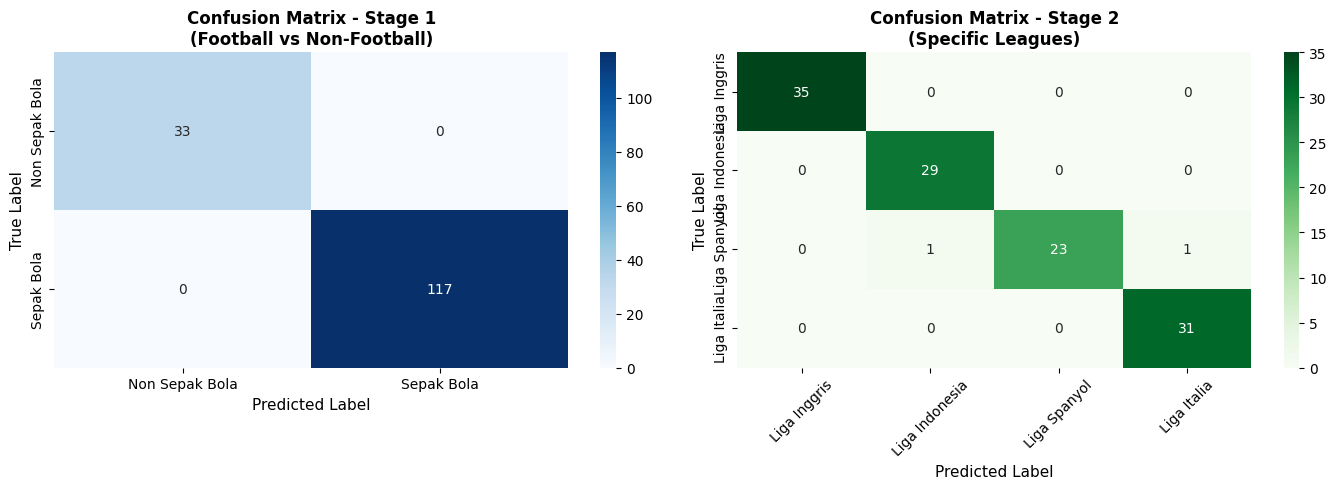

In [39]:
# Classification Report
print("Generating predictions for Stage 1...")
preds_stage1 = trainer2_1.predict(test_ds2_1)
y_pred_1 = np.argmax(preds_stage1.predictions, axis=1)
y_true_1 = preds_stage1.label_ids

print("Generating predictions for Stage 2...")
preds_stage2 = trainer2_2.predict(test_ds2_2)
y_pred_2 = np.argmax(preds_stage2.predictions, axis=1)
y_true_2 = preds_stage2.label_ids

target_names_1 = ['Non Sepak Bola', 'Sepak Bola']
print("\n--- CLASSIFICATION REPORT: STAGE 1 (Binary) ---")
print(classification_report(y_true_1, y_pred_1, target_names=target_names_1))

target_names_2 = ['Liga Inggris', 'Liga Indonesia', 'Liga Spanyol', 'Liga Italia']
print("\n--- CLASSIFICATION REPORT: STAGE 2 (Leagues) ---")
print(classification_report(y_true_2, y_pred_2, target_names=target_names_2))

# Confusion Matrix
cm1 = confusion_matrix(y_true_1, y_pred_1)
cm2 = confusion_matrix(y_true_2, y_pred_2)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.heatmap(cm1, annot=True, fmt='d', cmap='Blues',
            xticklabels=target_names_1, yticklabels=target_names_1, ax=axes[0])
axes[0].set_title('Confusion Matrix - Stage 1\n(Football vs Non-Football)', fontsize=12, fontweight='bold')
axes[0].set_xlabel('Predicted Label', fontsize=11)
axes[0].set_ylabel('True Label', fontsize=11)

sns.heatmap(cm2, annot=True, fmt='d', cmap='Greens',
            xticklabels=target_names_2, yticklabels=target_names_2, ax=axes[1])
axes[1].set_title('Confusion Matrix - Stage 2\n(Specific Leagues)', fontsize=12, fontweight='bold')
axes[1].set_xlabel('Predicted Label', fontsize=11)
axes[1].set_ylabel('True Label', fontsize=11)
axes[1].tick_params(axis='x', rotation=45)

plt.tight_layout()
plt.show()